<a href="https://colab.research.google.com/github/Aswini-Dileep/AI-ML-Project/blob/main/AI_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Comparative Analysis of K-Means Clustering Initialization Techniques Using a Real-World Wholesale Customers Dataset

## 1. Introduction

Clustering is an unsupervised machine learning technique used to group similar data points based on their characteristics. It is widely used in customer segmentation, market analysis, image processing, healthcare and many other domains.

K-Means is one of the most commonly used clustering algorithms. It partitions a dataset into K clusters by assigning each data point to its nearest centroid and iteratively updating the centroids until convergence.

However, the performance of K-Means depends significantly on the initial selection of centroids. Poor centroid initialization can lead to slower convergence, increased execution time and potentially different clustering solutions.

This research investigates the effect of different centroid initialization techniques on K-Means clustering performance using a real-world wholesale customer purchasing dataset.

## 1.2 Problem Statement

Traditional K-Means clustering commonly uses random centroid initialization. Since the initial centroids influence the clustering process, random initialization may result in unnecessary iterations, inconsistent convergence and variations in clustering quality.

Therefore, this research aims to investigate whether alternative centroid initialization techniques, particularly mean-based and median-based approaches, can improve the convergence efficiency and performance of K-Means clustering.

## 1.3 Research Objectives

1. To understand and implement the K-Means clustering algorithm.
2. To study the effect of different centroid initialization techniques.
3. To implement Random, Mean-based, Median-based and K-Means++ initialization methods.
4. To determine a suitable number of clusters using the Elbow Method and Silhouette Score.
5. To compare the initialization methods based on execution time, number of iterations, SSE and Silhouette Score.
6. To evaluate the stability of the initialization methods through repeated experiments.
7. To interpret the resulting customer segments using their purchasing patterns.

## 1.4 Dataset Description

This research uses the Wholesale Customers dataset from the UCI Machine Learning Repository.

The dataset contains 440 customer records and eight attributes describing annual spending across different product categories, along with customer channel and region information.

The six numerical spending attributes will be used for clustering. Channel and Region will be reserved for interpreting the resulting clusters.

## 1.5 Research Scope

The research focuses on comparing centroid initialization techniques within the K-Means algorithm. The experiments will use the same dataset, preprocessing approach, number of clusters and convergence criteria to ensure a fair comparison.

The study will evaluate clustering performance using:

- Number of iterations
- Execution time
- Sum of Squared Errors (SSE)
- Silhouette Score
- Stability across repeated runs

## 2. Dataset Loading and Initial Inspection

In this section, we load the Wholesale Customers dataset and perform an initial inspection to understand its structure, attributes, data types and data quality.

source: https://archive.ics.uci.edu/dataset/292/wholesale+customers?

In [165]:

# Cell 1: Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import silhouette_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [166]:

# Cell 2: Load dataset

df = pd.read_csv("/content/Wholesale customers data.csv")

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [167]:

# Cell 3: Display first five rows

df.head()


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [168]:
# Number of rows and columns

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)

Number of rows: 440
Number of columns: 8
Dataset shape: (440, 8)


The dataset contains 440 customer records and eight attributes.

In [169]:
# Display information about the dataset

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [170]:
# Count missing values in each column

print("Missing values:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

Total missing values: 0


There are no missing values in the dataset, so missing-value imputation is not required.

In [171]:
# Generate descriptive statistics

df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [172]:
# Check duplicate rows

duplicates = df.duplicated().sum()

print("Number of duplicate records:", duplicates)

Number of duplicate records: 0


## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the characteristics and patterns in the Wholesale Customers dataset.

The analysis focuses on customer spending across six product categories: Fresh, Milk, Grocery, Frozen, Detergents_Paper and Delicassen.

Statistical analysis and visualizations are used to investigate distributions, skewness, outliers and correlations between the spending variables. These observations will guide the preprocessing decisions before applying K-Means clustering.

In [173]:
# Select the six numerical spending features

features = [
    "Fresh",
    "Milk",
    "Grocery",
    "Frozen",
    "Detergents_Paper",
    "Delicassen"
]

X = df[features].copy()

print("Selected features:")
print(X.columns.tolist())

print("\nShape of selected dataset:", X.shape)

display(X.head())

Selected features:
['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']

Shape of selected dataset: (440, 6)


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


We select only the six spending variables because these represent the numerical purchasing behaviour of customers.

We exclude:
- Channel: Customer type (Horeca or Retail).
- Region: Customer geographical region.

We will use Channel and Region later to interpret the clusters, not as inputs to our initial Euclidean-distance clustering.

In [174]:
# Descriptive statistics of spending features

display(X.describe().T)

,count,mean,std,min,25%,50%,75%,max
Fresh,440.0,12000.297727,12647.328865,3.0,3127.75,8504.0,16933.75,112151.0
Milk,440.0,5796.265909,7380.377175,55.0,1533.00,3627.0,7190.25,73498.0
Grocery,440.0,7951.277273,9503.162829,3.0,2153.00,4755.5,10655.75,92780.0
Frozen,440.0,3071.931818,4854.673333,25.0,742.25,1526.0,3554.25,60869.0
Detergents_Paper,440.0,2881.493182,4767.854448,3.0,256.75,816.5,3922.00,40827.0
Delicassen,440.0,1524.870455,2820.105937,3.0,408.25,965.5,1820.25,47943.0


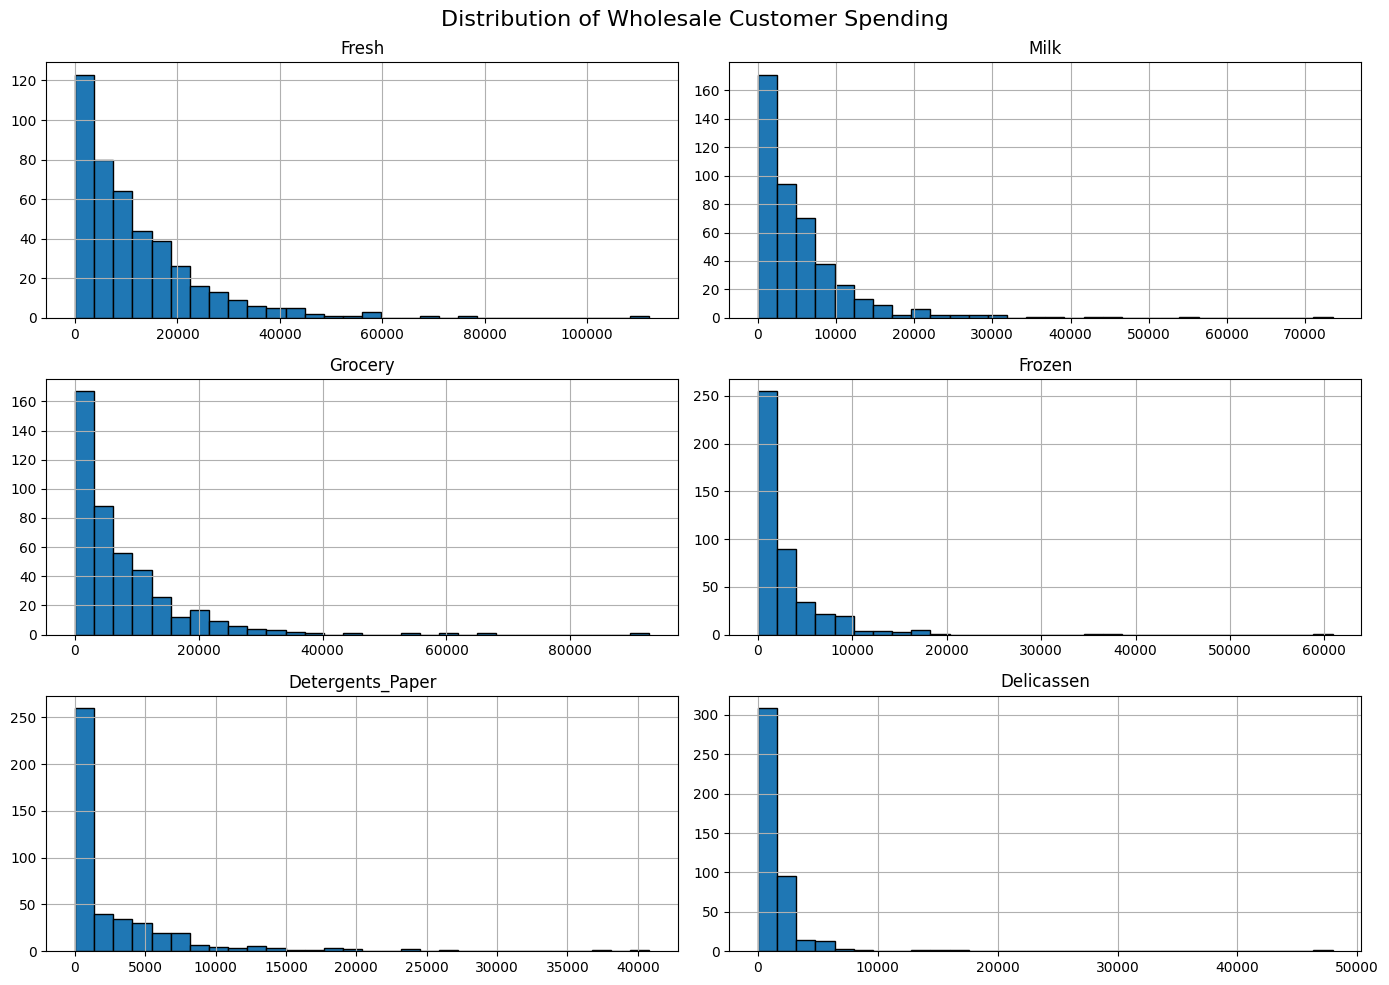

In [175]:
import matplotlib.pyplot as plt

# Plot histograms for all six spending features

X.hist(figsize=(14, 10), bins=30, edgecolor="black")

plt.suptitle("Distribution of Wholesale Customer Spending", fontsize=16)

plt.tight_layout()
plt.show()

In [176]:
# Calculate skewness for each spending feature

skewness = X.skew()

print("Skewness of spending features:\n")
print(skewness.sort_values(ascending=False))

Skewness of spending features:

Delicassen          11.151586
Frozen               5.907986
Milk                 4.053755
Detergents_Paper     3.631851
Grocery              3.587429
Fresh                2.561323
dtype: float64


use this general guide:

Skewness	Interpretation

Around 0	Approximately symmetric

0 to 0.5	Low positive skew

0.5 to 1	Moderate positive skew

Above 1	High positive skew

Below 0	Negative skew

These are approximate descriptive guidelines, not strict statistical rules.

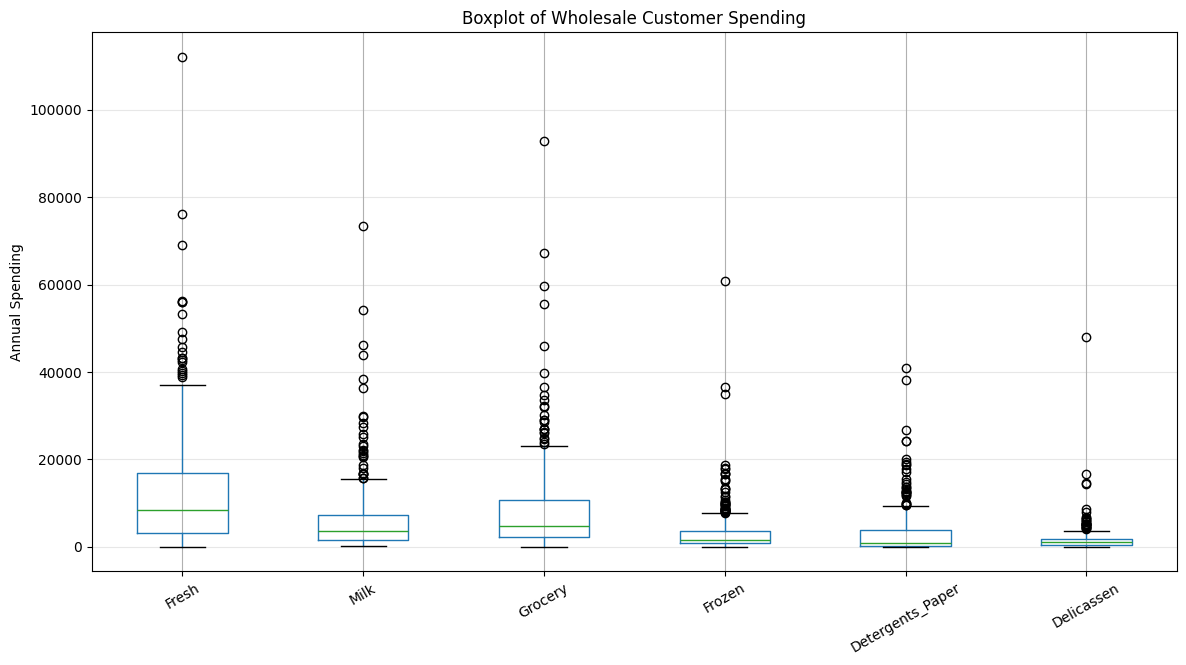

In [177]:
# Boxplots of original spending features

plt.figure(figsize=(14, 7))

X.boxplot()

plt.title("Boxplot of Wholesale Customer Spending")
plt.ylabel("Annual Spending")
plt.xticks(rotation=30)

plt.grid(axis="y", alpha=0.3)
plt.show()

In [178]:
# Detect potential outliers using IQR

outlier_counts = {}

for column in X.columns:

    Q1 = X[column].quantile(0.25)
    Q3 = X[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = X[
        (X[column] < lower_limit) |
        (X[column] > upper_limit)
    ]

    outlier_counts[column] = len(outliers)

print("Potential outliers in each feature:\n")

for column, count in outlier_counts.items():
    print(f"{column}: {count}")

Potential outliers in each feature:

Fresh: 20
Milk: 28
Grocery: 24
Frozen: 43
Detergents_Paper: 30
Delicassen: 27


These are potential statistical outliers, not necessarily incorrect records.

In [179]:
# Calculate Pearson correlation coefficients

pearson_corr = X.corr(method="pearson")

print("Pearson Correlation Matrix:\n")

display(pearson_corr.round(3))

Pearson Correlation Matrix:



,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Fresh,1.000,0.101,-0.012,0.346,-0.102,0.245
Milk,0.101,1.000,0.728,0.124,0.662,0.406
Grocery,-0.012,0.728,1.000,-0.040,0.925,0.205
Frozen,0.346,0.124,-0.040,1.000,-0.132,0.391
Detergents_Paper,-0.102,0.662,0.925,-0.132,1.000,0.069
Delicassen,0.245,0.406,0.205,0.391,0.069,1.000


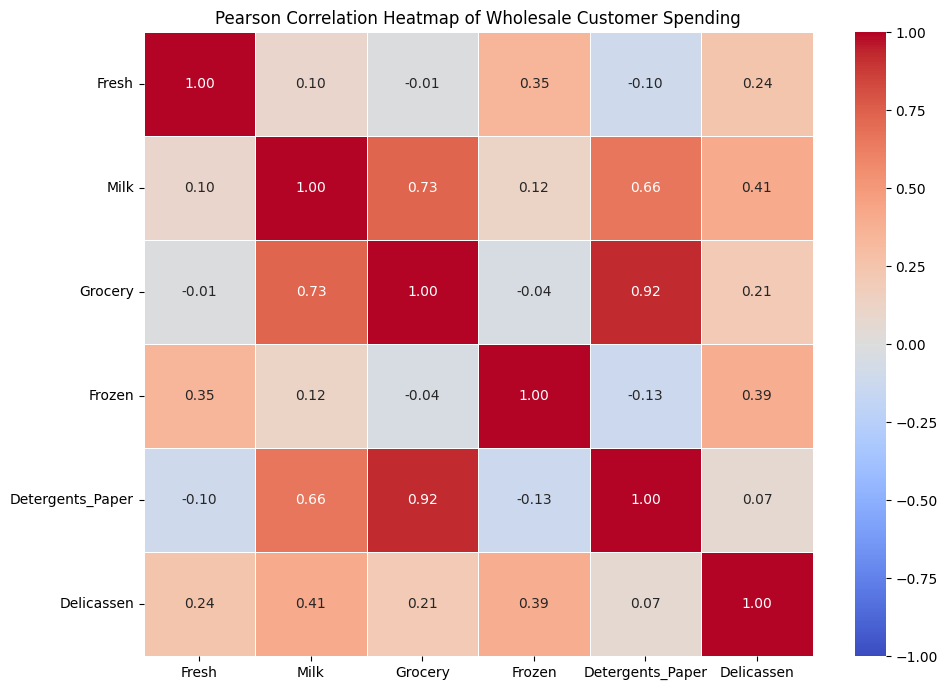

In [180]:
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.heatmap(
    pearson_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Pearson Correlation Heatmap of Wholesale Customer Spending")

plt.tight_layout()
plt.show()

In [181]:
# Customer distribution by channel

print("Customer distribution by Channel:")
print(df["Channel"].value_counts())

print("\nCustomer distribution by Region:")
print(df["Region"].value_counts())

Customer distribution by Channel:
Channel
1    298
2    142
Name: count, dtype: int64

Customer distribution by Region:
Region
3    316
1     77
2     47
Name: count, dtype: int64


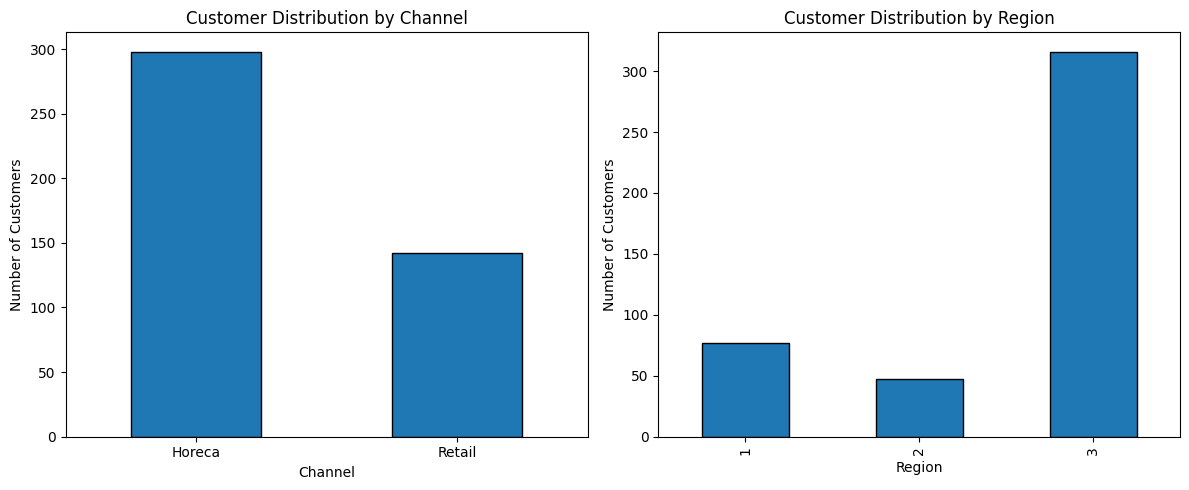

In [182]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df["Channel"].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[0],
    edgecolor="black"
)

axes[0].set_title("Customer Distribution by Channel")
axes[0].set_xlabel("Channel")
axes[0].set_ylabel("Number of Customers")
axes[0].set_xticklabels(["Horeca", "Retail"], rotation=0)

df["Region"].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[1],
    edgecolor="black"
)

axes[1].set_title("Customer Distribution by Region")
axes[1].set_xlabel("Region")
axes[1].set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

## 4. Data Preprocessing

Data preprocessing is performed to prepare the customer spending attributes for K-Means clustering.

The spending variables may have different numerical scales and skewed distributions. Therefore, alternative transformation and scaling approaches are investigated to reduce the influence of scale differences and extreme values.

In [183]:
# Import preprocessing libraries

from sklearn.preprocessing import StandardScaler, RobustScaler
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Preprocessing libraries imported successfully!")

Preprocessing libraries imported successfully!


In [184]:
# Select the six spending features

features = [
    "Fresh",
    "Milk",
    "Grocery",
    "Frozen",
    "Detergents_Paper",
    "Delicassen"
]

X = df[features].copy()

print("Original data shape:", X.shape)

display(X.head())

Original data shape: (440, 6)


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


In [185]:
# Check minimum values in each feature

print("Minimum values:")
print(X.min())

print("\nAre all values non-negative?")
print((X >= 0).all().all())

Minimum values:
Fresh                3
Milk                55
Grocery              3
Frozen              25
Detergents_Paper     3
Delicassen           3
dtype: int64

Are all values non-negative?
True


In [186]:
# Apply log1p transformation

X_log = np.log1p(X)

print("Log transformation completed!")

display(X_log.head())

Log transformation completed!


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,9.446992,9.175438,8.930891,5.370638,7.891705,7.199678
1,8.861917,9.191259,9.166284,7.474772,8.099858,7.482682
2,8.756840,9.083529,8.947026,7.785721,8.165364,8.967632
3,9.492960,7.087574,8.348064,8.764834,6.230481,7.489412
4,10.026413,8.596189,8.881697,8.272826,7.483244,8.553718


In [187]:
# Compare original and transformed skewness

skew_comparison = pd.DataFrame({
    "Original Skewness": X.skew(),
    "Log Transformed Skewness": X_log.skew()
})

display(skew_comparison.round(3))

,Original Skewness,Log Transformed Skewness
Fresh,2.561,-1.575
Milk,4.054,-0.224
Grocery,3.587,-0.675
Frozen,5.908,-0.353
Detergents_Paper,3.632,-0.236
Delicassen,11.152,-1.092


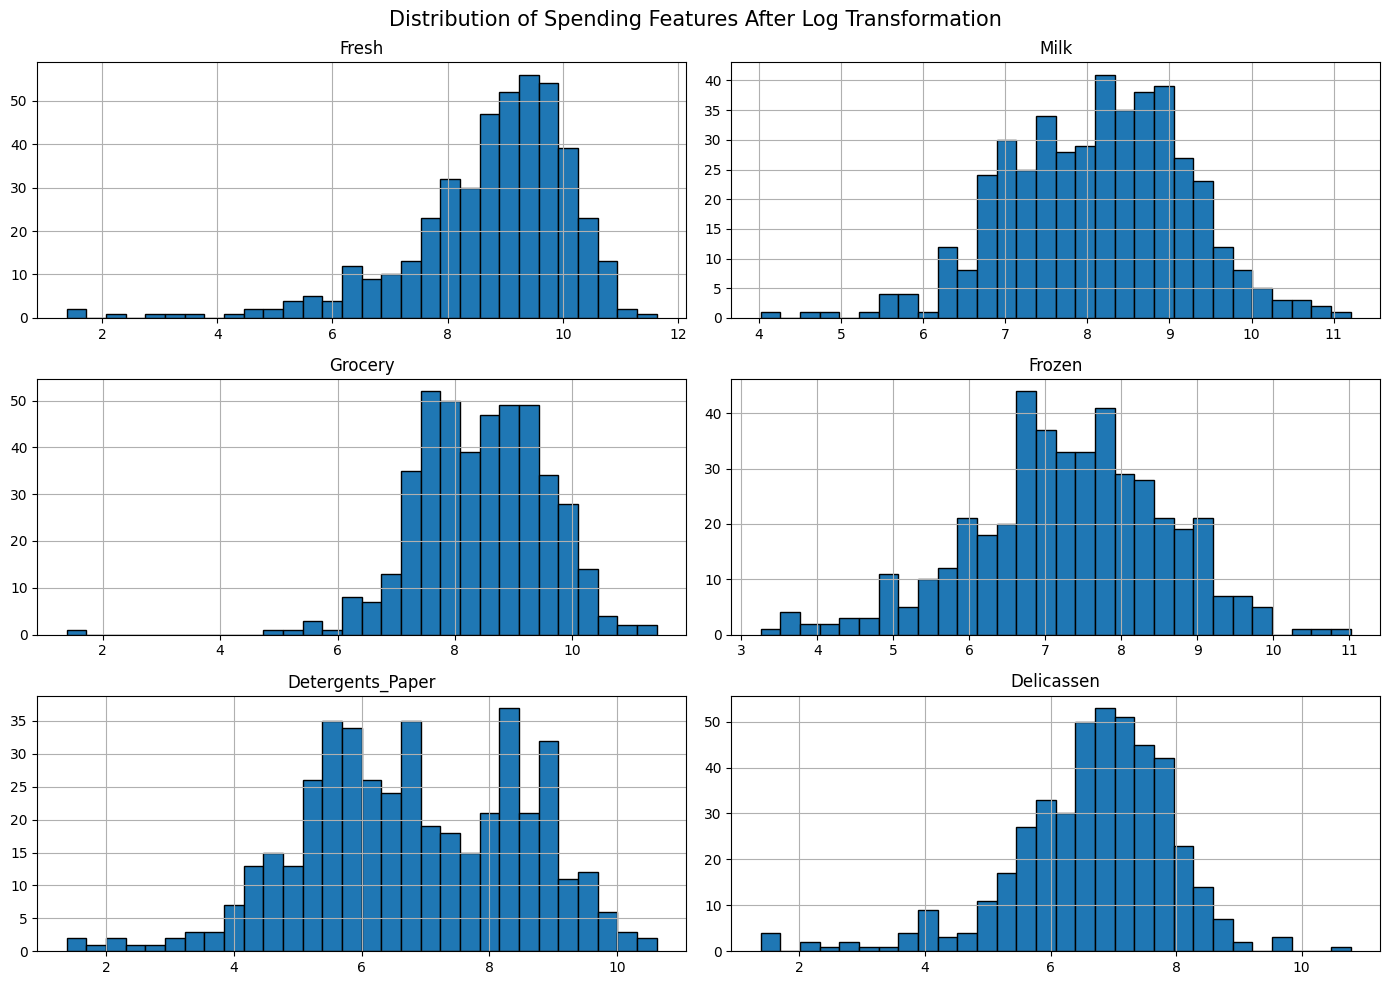

In [188]:
# Plot histograms after log transformation

X_log.hist(
    figsize=(14, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Spending Features After Log Transformation",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [189]:
# Standardize the log-transformed data

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_log)

# Convert back to DataFrame for easier inspection

X_scaled = pd.DataFrame(
    X_scaled,
    columns=features,
    index=X.index
)

print("Scaled dataset shape:", X_scaled.shape)

display(X_scaled.head())

Scaled dataset shape: (440, 6)


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.486184,0.976299,0.440155,-1.509250,0.644143,0.408966
1,0.087889,0.990956,0.652171,0.134052,0.766043,0.627926
2,0.016356,0.891151,0.454687,0.376899,0.804405,1.776833
3,0.517477,-0.957973,-0.084792,1.141574,-0.328712,0.633133
4,0.880631,0.439662,0.395847,0.757322,0.404939,1.456588


In [190]:
# Check mean and standard deviation after scaling

scaling_summary = pd.DataFrame({
    "Mean": X_scaled.mean(),
    "Standard Deviation": X_scaled.std()
})

display(scaling_summary.round(3))

,Mean,Standard Deviation
Fresh,0.0,1.001
Milk,-0.0,1.001
Grocery,-0.0,1.001
Frozen,0.0,1.001
Detergents_Paper,-0.0,1.001
Delicassen,-0.0,1.001


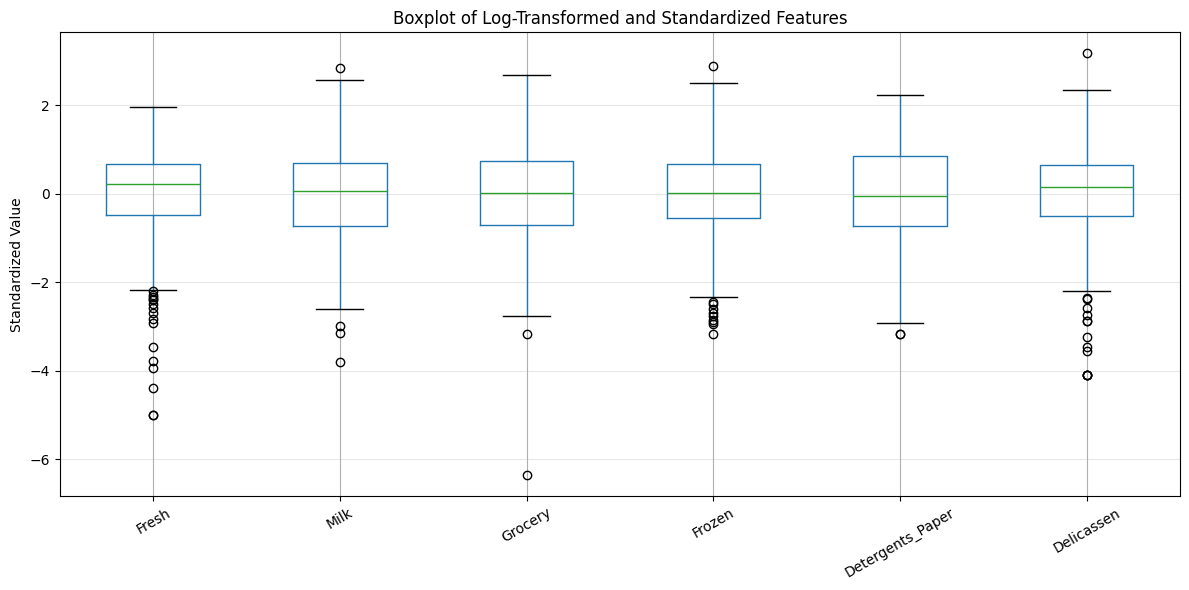

In [191]:
# Boxplot of scaled features

plt.figure(figsize=(12, 6))

X_scaled.boxplot()

plt.title("Boxplot of Log-Transformed and Standardized Features")
plt.ylabel("Standardized Value")
plt.xticks(rotation=30)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [192]:
# Approach A: StandardScaler on original data

scaler_original = StandardScaler()

X_standard = pd.DataFrame(
    scaler_original.fit_transform(X),
    columns=features,
    index=X.index
)

# Approach B: Log1p + StandardScaler

scaler_log = StandardScaler()

X_log_standard = pd.DataFrame(
    scaler_log.fit_transform(X_log),
    columns=features,
    index=X.index
)

# Compare average absolute skewness

comparison = pd.DataFrame({
    "Original + StandardScaler": X_standard.skew(),
    "Log1p + StandardScaler": X_log_standard.skew()
})

display(comparison.round(3))

print(
    "Average absolute skewness - Original:",
    round(X_standard.skew().abs().mean(), 3)
)

print(
    "Average absolute skewness - Log transformed:",
    round(X_log_standard.skew().abs().mean(), 3)
)

,Original + StandardScaler,Log1p + StandardScaler
Fresh,2.561,-1.575
Milk,4.054,-0.224
Grocery,3.587,-0.675
Frozen,5.908,-0.353
Detergents_Paper,3.632,-0.236
Delicassen,11.152,-1.092


Average absolute skewness - Original: 5.149
Average absolute skewness - Log transformed: 0.692


In [193]:
# Final candidate dataset for clustering

X_final = X_log_standard.copy()

print("Final dataset shape:", X_final.shape)

print("\nFinal feature names:")
print(X_final.columns.tolist())

display(X_final.head())

Final dataset shape: (440, 6)

Final feature names:
['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.486184,0.976299,0.440155,-1.509250,0.644143,0.408966
1,0.087889,0.990956,0.652171,0.134052,0.766043,0.627926
2,0.016356,0.891151,0.454687,0.376899,0.804405,1.776833
3,0.517477,-0.957973,-0.084792,1.141574,-0.328712,0.633133
4,0.880631,0.439662,0.395847,0.757322,0.404939,1.456588


## 5. Determining the Optimal Number of Clusters

The K-Means algorithm requires the number of clusters (K) to be specified in advance. Selecting an appropriate value of K is important because it influences the resulting cluster assignments and clustering quality.

In this research, the Elbow Method and Silhouette Score are used to investigate the appropriate number of clusters.

The Elbow Method evaluates the reduction in within-cluster Sum of Squared Errors (SSE), while the Silhouette Score measures cluster cohesion and separation.

In [194]:
# Import K-Means and evaluation metrics

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import matplotlib.pyplot as plt
import pandas as pd

In [195]:
# Calculate SSE for K values from 1 to 10

sse_values = []

K_range = range(1, 11)

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    kmeans.fit(X_final)

    sse_values.append(kmeans.inertia_)

# Display results

elbow_results = pd.DataFrame({
    "Number of Clusters (K)": list(K_range),
    "SSE": sse_values
})

display(elbow_results)

,Number of Clusters (K),SSE
0,1,2640.000000
1,2,1844.064069
2,3,1553.421327
3,4,1386.862741
4,5,1266.149362
5,6,1174.758633
6,7,1086.358700
7,8,1028.486217
8,9,973.141483
9,10,931.998464


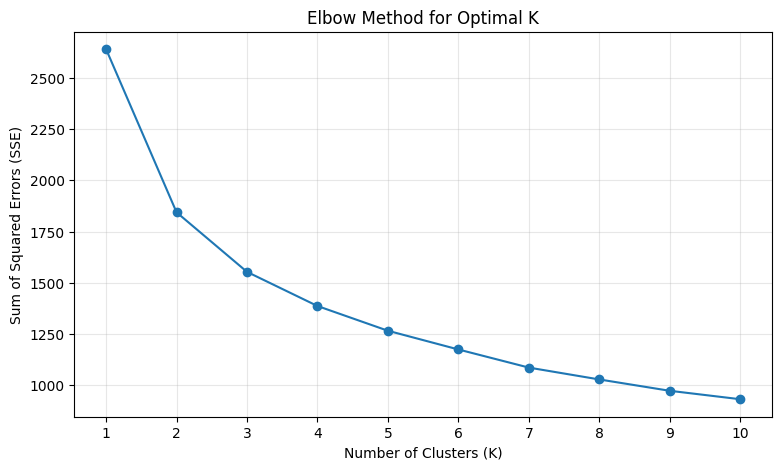

In [196]:
plt.figure(figsize=(9, 5))

plt.plot(
    list(K_range),
    sse_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Sum of Squared Errors (SSE)")
plt.title("Elbow Method for Optimal K")

plt.xticks(list(K_range))
plt.grid(True, alpha=0.3)

plt.show()

Interpretation:
- SSE decreases significantly when moving from K=1 to K=2.
- It continues to decrease from K=2 to K=3.
- After K=3, the reduction becomes more gradual.

The elbow appears approximately around K=2–3. There isn't an extremely sharp elbow, so we should not claim that the Elbow Method identifies one uniquely obvious value.

In [197]:
# Calculate silhouette scores for K values from 2 to 10

silhouette_values = []

K_silhouette = range(2, 11)

for k in K_silhouette:

    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    labels = kmeans.fit_predict(X_final)

    score = silhouette_score(X_final, labels)

    silhouette_values.append(score)

# Display results

silhouette_results = pd.DataFrame({
    "Number of Clusters (K)": list(K_silhouette),
    "Silhouette Score": silhouette_values
})

display(silhouette_results)

,Number of Clusters (K),Silhouette Score
0,2,0.290328
1,3,0.259416
2,4,0.188495
3,5,0.191585
4,6,0.200887
5,7,0.195780
6,8,0.185175
7,9,0.196501
8,10,0.190523


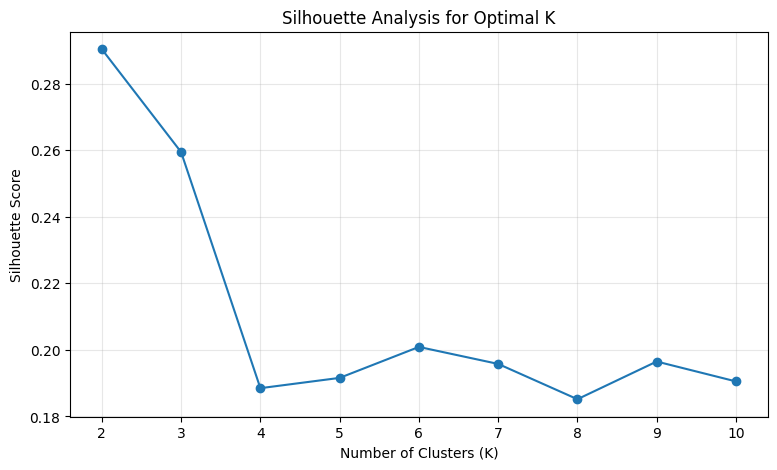

In [198]:
plt.figure(figsize=(9, 5))

plt.plot(
    list(K_silhouette),
    silhouette_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis for Optimal K")

plt.xticks(list(K_silhouette))
plt.grid(True, alpha=0.3)

plt.show()

Interpretation:
- K=2 produces the highest Silhouette Score (0.2903).
- K=3 has the second-highest score (0.2594).
- The scores decrease considerably from K=3 to K=4.
- The relatively low scores indicate that the clusters are not very strongly separated.

This suggests that the dataset may contain overlapping customer spending patterns.

In [199]:
# Combine Elbow and Silhouette results

k_comparison = pd.DataFrame({
    "K": list(K_silhouette),
    "SSE": sse_values[1:],
    "Silhouette Score": silhouette_values
})

display(k_comparison.round(4))

,K,SSE,Silhouette Score
0,2,1844.0641,0.2903
1,3,1553.4213,0.2594
2,4,1386.8627,0.1885
3,5,1266.1494,0.1916
4,6,1174.7586,0.2009
5,7,1086.3587,0.1958
6,8,1028.4862,0.1852
7,9,973.1415,0.1965
8,10,931.9985,0.1905


In [200]:
best_silhouette_index = silhouette_results[
    "Silhouette Score"
].idxmax()

best_k_silhouette = int(
    silhouette_results.loc[
        best_silhouette_index,
        "Number of Clusters (K)"
    ]
)

print("K with highest Silhouette Score:", best_k_silhouette)

K with highest Silhouette Score: 2


### 5.4 Selection of the Optimal Number of Clusters

The optimal number of clusters was investigated using the Elbow Method and Silhouette Score.

The Elbow curve showed a substantial reduction in SSE between K=1 and K=2, followed by progressively smaller reductions as the number of clusters increased. The curve suggested a possible elbow around K=2 to K=3.

The Silhouette analysis identified K=2 as the best-performing configuration, with a score of 0.2903. K=3 achieved the second-highest score of 0.2594.

Based on these observations, K=2 was selected for the primary comparative experiments because it achieved the highest Silhouette Score and was consistent with the initial reduction pattern in the Elbow curve. K=3 will additionally be considered in a sensitivity experiment.

The relatively modest Silhouette Scores indicate that the customer groups may have overlapping spending characteristics. Therefore, the resulting clusters will be interpreted with appropriate caution.

## 6. Implementation of K-Means Clustering from Scratch

In this section, the K-Means clustering algorithm is implemented from scratch using Python and NumPy.

The implementation separates centroid initialization from the main clustering procedure. This allows different initialization techniques to be compared using the same assignment, centroid-update and convergence procedures.

The selected primary number of clusters is K=2.

In [201]:
import numpy as np
import time

from sklearn.metrics import silhouette_score

# Experimental parameters

K = 2
MAX_ITER = 300
TOL = 1e-6

# Convert the final processed data into a NumPy array

data = X_final.to_numpy()

print("Data shape:", data.shape)
print("Number of clusters:", K)
print("Maximum iterations:", MAX_ITER)
print("Convergence tolerance:", TOL)

Data shape: (440, 6)
Number of clusters: 2
Maximum iterations: 300
Convergence tolerance: 1e-06


In [202]:
def euclidean_distance(point1, point2):

    distance = np.sqrt(np.sum((point1 - point2) ** 2))

    return distance

In [203]:
def assign_clusters(data, centroids):

    distances = np.zeros((len(data), len(centroids)))

    for i in range(len(data)):

        for j in range(len(centroids)):

            distances[i, j] = euclidean_distance(
                data[i],
                centroids[j]
            )

    labels = np.argmin(distances, axis=1)

    return labels

In [204]:
def update_centroids(data, labels, K, old_centroids):

    new_centroids = []

    for k in range(K):

        cluster_points = data[labels == k]

        if len(cluster_points) > 0:

            centroid = np.mean(cluster_points, axis=0)

        else:

            centroid = old_centroids[k]

        new_centroids.append(centroid)

    return np.array(new_centroids)

In [205]:
def calculate_sse(data, labels, centroids):

    sse = 0

    for i in range(len(data)):

        centroid = centroids[labels[i]]

        sse += np.sum((data[i] - centroid) ** 2)

    return sse

In [206]:
def kmeans_algorithm(data, initial_centroids,
                     K, max_iter=300, tol=1e-6):

    centroids = initial_centroids.copy()

    for iteration in range(max_iter):

        # Step 1: Assign points to nearest centroid
        labels = assign_clusters(data, centroids)

        # Step 2: Calculate new centroids
        new_centroids = update_centroids(
            data, labels, K, centroids
        )

        # Step 3: Calculate centroid movement
        movement = np.linalg.norm(
            new_centroids - centroids
        )

        centroids = new_centroids

        # Step 4: Check convergence
        if movement < tol:
            break

    # Reassign using the final centroids
    labels = assign_clusters(data, centroids)

    # Calculate final SSE
    sse = calculate_sse(data, labels, centroids)

    return labels, centroids, iteration + 1, sse

In [207]:
# Generate random initial centroids

np.random.seed(42)

random_indices = np.random.choice(
    len(data),
    size=K,
    replace=False
)

initial_centroids = data[random_indices]

# Run K-Means

labels, centroids, iterations, sse = kmeans_algorithm(
    data,
    initial_centroids,
    K
)

silhouette = silhouette_score(data, labels)

print("K-Means Results")
print("-----------------------")
print("Number of clusters:", K)
print("Number of iterations:", iterations)
print("SSE:", round(sse, 4))
print("Silhouette Score:", round(silhouette, 4))
print("Cluster sizes:", np.bincount(labels))

K-Means Results
-----------------------
Number of clusters: 2
Number of iterations: 13
SSE: 1844.0641
Silhouette Score: 0.2903
Cluster sizes: [188 252]


## 7. Implementation of Centroid Initialization Techniques

The initial selection of centroids plays an important role in K-Means clustering.

In this section, four centroid initialization techniques are implemented and evaluated:

1. Random initialization
2. Mean-based initialization
3. Median-based initialization
4. K-Means++ initialization

Each initialization technique will generate the initial centroids, which will then be passed to the same K-Means algorithm. This ensures that differences in the results can be attributed to the initialization techniques rather than changes in the clustering procedure.

In [208]:
def random_initialization(data, K, random_state=None):

    rng = np.random.default_rng(random_state)

    indices = rng.choice(
        len(data),
        size=K,
        replace=False
    )

    return data[indices].copy()

In [209]:
def mean_initialization(data, K, feature_index=0):

    sorted_indices = np.argsort(data[:, feature_index])

    groups = np.array_split(sorted_indices, K)

    centroids = []

    for group in groups:

        centroid = np.mean(data[group], axis=0)

        centroids.append(centroid)

    return np.array(centroids)

In [210]:
def median_initialization(data, K, feature_index=0):

    sorted_indices = np.argsort(data[:, feature_index])

    groups = np.array_split(sorted_indices, K)

    centroids = []

    for group in groups:

        centroid = np.median(data[group], axis=0)

        centroids.append(centroid)

    return np.array(centroids)

In [211]:
def kmeans_plus_plus_initialization(data, K, random_state=None):

    rng = np.random.default_rng(random_state)

    centroids = []

    # Select first centroid randomly
    first_index = rng.integers(len(data))

    centroids.append(data[first_index].copy())

    # Select remaining centroids
    for _ in range(1, K):

        distances = np.array([
            min(
                np.sum((point - centroid) ** 2)
                for centroid in centroids
            )
            for point in data
        ])

        probabilities = distances / distances.sum()

        next_index = rng.choice(
            len(data),
            p=probabilities
        )

        centroids.append(data[next_index].copy())

    return np.array(centroids)

In [212]:
# Generate initial centroids using all four methods

centroids_random = random_initialization(
    data, K, random_state=42
)

centroids_mean = mean_initialization(data, K)

centroids_median = median_initialization(data, K)

centroids_kpp = kmeans_plus_plus_initialization(
    data, K, random_state=42
)

# Display initial centroids

print("Random centroids:\n", centroids_random)

print("\nMean centroids:\n", centroids_mean)

print("\nMedian centroids:\n", centroids_median)

print("\nK-Means++ centroids:\n", centroids_kpp)

Random centroids:
 [[ 1.49981425 -1.6683685  -1.47396369  1.48974325 -0.83773097  1.01139487]
 [-1.89754556  0.16575151  0.66172088 -1.04617017  1.22981684  0.42780284]]

Mean centroids:
 [[-0.71339018  0.06075011  0.08836333 -0.27650056  0.17392896 -0.18709021]
 [ 0.71339018 -0.06075011 -0.08836333  0.27650056 -0.17392896  0.18709021]]

Median centroids:
 [[-0.46773577  0.16873337  0.24701133 -0.22376809  0.23447683 -0.03844427]
 [ 0.68372405 -0.05353915 -0.09692779  0.35365794 -0.2341838   0.26801787]]

K-Means++ centroids:
 [[ 1.49981425 -1.6683685  -1.47396369  1.48974325 -0.83773097  1.01139487]
 [-1.69417102  0.76384502  1.30738353 -0.3587681   1.4067457  -0.0742897 ]]


In [213]:
# Store initialization methods

initialization_methods = {
    "Random": centroids_random,
    "Mean": centroids_mean,
    "Median": centroids_median,
    "K-Means++": centroids_kpp
}

results = []

for method, initial_centroids in initialization_methods.items():

    labels, centroids, iterations, sse = kmeans_algorithm(
        data,
        initial_centroids,
        K
    )

    silhouette = silhouette_score(data, labels)

    results.append({
        "Method": method,
        "Iterations": iterations,
        "SSE": sse,
        "Silhouette Score": silhouette
    })

# Display comparison

comparison_df = pd.DataFrame(results)

display(comparison_df.round(4))

,Method,Iterations,SSE,Silhouette Score
0,Random,8,1844.0641,0.2903
1,Mean,8,1844.1270,0.2905
2,Median,7,1844.1270,0.2905
3,K-Means++,8,1844.0641,0.2903


### 7.8 Initial Comparison of Centroid Initialization Methods

An initial experiment was conducted using K=2 to compare the four centroid initialization techniques.

Random and K-Means++ initialization converged in 8 iterations, producing an SSE of 1844.0641 and a Silhouette Score of 0.2903.

Mean initialization converged in 8 iterations, while Median initialization converged in 7 iterations. Both methods produced an SSE of 1844.1270 and a Silhouette Score of 0.2905.

The initial results indicate that all four methods reached similar clustering solutions. Median initialization required the fewest iterations in this particular run. However, the small differences in SSE and Silhouette Score are insufficient to establish the superiority of any method.

Further repeated experiments are required to evaluate convergence speed, execution time and stability.

## 8. Repeated Comparative Experiments

To evaluate the performance and stability of the initialization techniques, repeated experiments are conducted using 30 trials.

Random and K-Means++ initialization use different random seeds in each trial.

For the Mean and Median methods, the sorting feature is selected from the six spending attributes using a reproducible trial-specific random seed. This allows us to investigate the sensitivity of these feature-guided initialization methods to the selected sorting feature.

All methods use the same K-Means implementation, dataset, number of clusters and convergence criteria.

In [214]:
# Number of repeated trials

N_RUNS = 30

# Store all experimental results

all_results = []

# Run experiments

for run in range(N_RUNS):

    seed = 100 + run

    # Random initialization
    initial_random = random_initialization(
        data, K, random_state=seed
    )

    # Mean initialization with trial-specific sorting feature
    rng_mean = np.random.default_rng(seed)

    mean_feature = rng_mean.integers(0, data.shape[1])

    initial_mean = mean_initialization(
        data, K, feature_index=mean_feature
    )

    # Median initialization with trial-specific sorting feature
    rng_median = np.random.default_rng(seed)

    median_feature = rng_median.integers(0, data.shape[1])

    initial_median = median_initialization(
        data, K, feature_index=median_feature
    )

    # K-Means++ initialization
    initial_kpp = kmeans_plus_plus_initialization(
        data, K, random_state=seed
    )

    # Store initialization methods
    methods = {
        "Random": initial_random,
        "Mean": initial_mean,
        "Median": initial_median,
        "K-Means++": initial_kpp
    }

    # Run K-Means for each method
    for method, initial_centroids in methods.items():

        start_time = time.perf_counter()

        labels, centroids, iterations, sse = kmeans_algorithm(
            data,
            initial_centroids,
            K
        )

        execution_time = time.perf_counter() - start_time

        silhouette = silhouette_score(data, labels)

        all_results.append({
            "Run": run + 1,
            "Method": method,
            "Iterations": iterations,
            "Execution Time": execution_time,
            "SSE": sse,
            "Silhouette Score": silhouette
        })

print("Repeated experiments completed!")

Repeated experiments completed!


In [215]:
# Convert results into a DataFrame

results_df = pd.DataFrame(all_results)

display(results_df.head(12))

print("Total experimental runs:", len(results_df))

,Run,Method,Iterations,Execution Time,SSE,Silhouette Score
0,1,Random,17,0.145570,1844.064069,0.290328
1,1,Mean,10,0.120127,1844.064069,0.290328
2,1,Median,9,0.109172,1844.064069,0.290328
3,1,K-Means++,17,0.162756,1844.064069,0.290328
4,2,Random,10,0.124156,1844.064069,0.290328
5,2,Mean,12,0.130871,1844.064069,0.290328
6,2,Median,11,0.123412,1844.064069,0.290328
7,2,K-Means++,18,0.167183,1844.064069,0.290328
8,3,Random,9,0.107291,1844.127031,0.290488
9,3,Mean,11,0.124992,1844.064069,0.290328


Total experimental runs: 120


In [216]:
# Calculate average performance for each method

average_results = results_df.groupby("Method").agg({
    "Iterations": "mean",
    "Execution Time": "mean",
    "SSE": "mean",
    "Silhouette Score": "mean"
}).reset_index()

display(average_results.round(6))

,Method,Iterations,Execution Time,SSE,Silhouette Score
0,K-Means++,12.533333,0.147036,1844.072464,0.290350
1,Mean,10.233333,0.127360,1844.089254,0.290392
2,Median,9.300000,0.118443,1844.089254,0.290392
3,Random,12.200000,0.139900,1844.082957,0.290376


In [217]:
# Calculate standard deviation for each method

stability_results = results_df.groupby("Method").agg({
    "Iterations": "std",
    "Execution Time": "std",
    "SSE": "std",
    "Silhouette Score": "std"
}).reset_index()

stability_results.columns = [
    "Method",
    "Iterations Std",
    "Execution Time Std",
    "SSE Std",
    "Silhouette Std"
]

display(stability_results.round(6))

,Method,Iterations Std,Execution Time Std,SSE Std,Silhouette Std
0,K-Means++,4.407934,0.039460,0.021769,0.000055
1,Mean,2.144493,0.030181,0.031372,0.000080
2,Median,2.306662,0.031902,0.031372,0.000080
3,Random,4.373904,0.040224,0.029346,0.000075


8.3 Important experimental clarification

Our Mean and Median methods now use a trial-specific sorting feature, selected from the six spending features. This means they are feature-guided variants rather than repeated identical deterministic runs.

Also, the runtime currently recorded in your code measures only the K-Means execution, not the time required to generate the initial centroids. Before finalizing the runtime comparison, we should measure the complete initialization-plus-clustering process consistently for all four methods.

In [218]:
# Repeat experiments with end-to-end runtime measurement

N_RUNS = 30
all_results = []

for run in range(N_RUNS):

    seed = 100 + run

    # Random initialization
    start_time = time.perf_counter()

    initial_random = random_initialization(
        data, K, random_state=seed
    )

    labels, centroids, iterations, sse = kmeans_algorithm(
        data, initial_random, K
    )

    random_time = time.perf_counter() - start_time

    all_results.append({
        "Run": run + 1,
        "Method": "Random",
        "Iterations": iterations,
        "Execution Time": random_time,
        "SSE": sse,
        "Silhouette Score": silhouette_score(data, labels)
    })

    # Select a sorting feature for Mean and Median
    rng = np.random.default_rng(seed)
    feature_index = rng.integers(0, data.shape[1])

    # Mean initialization
    start_time = time.perf_counter()

    initial_mean = mean_initialization(
        data, K, feature_index
    )

    labels, centroids, iterations, sse = kmeans_algorithm(
        data, initial_mean, K
    )

    mean_time = time.perf_counter() - start_time

    all_results.append({
        "Run": run + 1,
        "Method": "Mean",
        "Iterations": iterations,
        "Execution Time": mean_time,
        "SSE": sse,
        "Silhouette Score": silhouette_score(data, labels)
    })

    # Median initialization
    start_time = time.perf_counter()

    initial_median = median_initialization(
        data, K, feature_index
    )

    labels, centroids, iterations, sse = kmeans_algorithm(
        data, initial_median, K
    )

    median_time = time.perf_counter() - start_time

    all_results.append({
        "Run": run + 1,
        "Method": "Median",
        "Iterations": iterations,
        "Execution Time": median_time,
        "SSE": sse,
        "Silhouette Score": silhouette_score(data, labels)
    })

    # K-Means++ initialization
    start_time = time.perf_counter()

    initial_kpp = kmeans_plus_plus_initialization(
        data, K, random_state=seed
    )

    labels, centroids, iterations, sse = kmeans_algorithm(
        data, initial_kpp, K
    )

    kpp_time = time.perf_counter() - start_time

    all_results.append({
        "Run": run + 1,
        "Method": "K-Means++",
        "Iterations": iterations,
        "Execution Time": kpp_time,
        "SSE": sse,
        "Silhouette Score": silhouette_score(data, labels)
    })

# Create new results DataFrame
results_df = pd.DataFrame(all_results)

print("Total experiments:", len(results_df))

Total experiments: 120


In [219]:
average_results = results_df.groupby("Method").agg({
    "Iterations": "mean",
    "Execution Time": "mean",
    "SSE": "mean",
    "Silhouette Score": "mean"
}).reset_index()

display(average_results.round(6))

,Method,Iterations,Execution Time,SSE,Silhouette Score
0,K-Means++,12.533333,0.158065,1844.072464,0.290350
1,Mean,10.233333,0.135062,1844.089254,0.290392
2,Median,9.300000,0.126966,1844.089254,0.290392
3,Random,12.200000,0.150398,1844.082957,0.290376


In [220]:
stability_results = results_df.groupby("Method").agg({
    "Iterations": "std",
    "Execution Time": "std",
    "SSE": "std",
    "Silhouette Score": "std"
}).reset_index()

display(stability_results.round(6))

,Method,Iterations,Execution Time,SSE,Silhouette Score
0,K-Means++,4.407934,0.055814,0.021769,0.000055
1,Mean,2.144493,0.028257,0.031372,0.000080
2,Median,2.306662,0.030222,0.031372,0.000080
3,Random,4.373904,0.055181,0.029346,0.000075


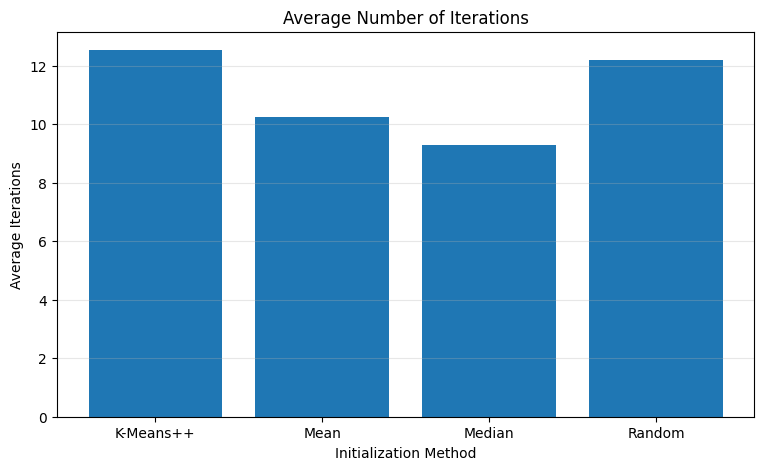

In [221]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    average_results["Method"],
    average_results["Iterations"]
)

plt.title("Average Number of Iterations")
plt.xlabel("Initialization Method")
plt.ylabel("Average Iterations")

plt.grid(axis="y", alpha=0.3)
plt.show()

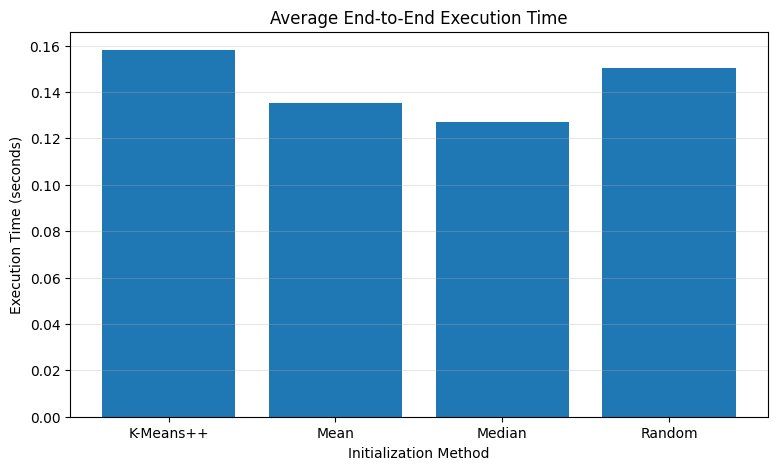

In [222]:
plt.figure(figsize=(9, 5))

plt.bar(
    average_results["Method"],
    average_results["Execution Time"]
)

plt.title("Average End-to-End Execution Time")
plt.xlabel("Initialization Method")
plt.ylabel("Execution Time (seconds)")

plt.grid(axis="y", alpha=0.3)
plt.show()

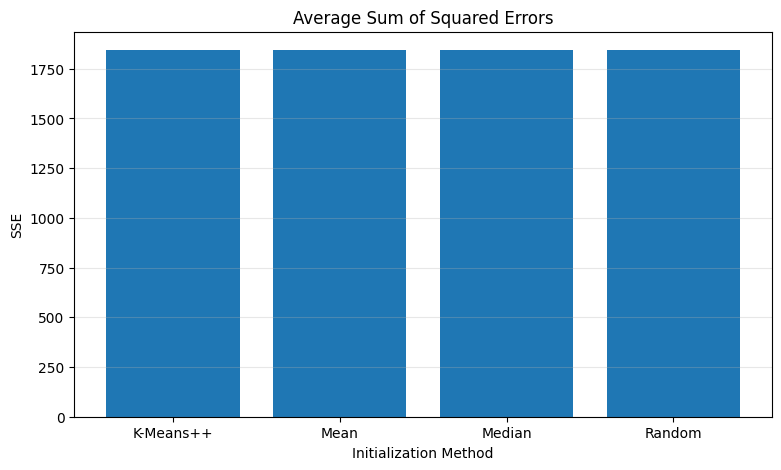

In [223]:
plt.figure(figsize=(9, 5))

plt.bar(
    average_results["Method"],
    average_results["SSE"]
)

plt.title("Average Sum of Squared Errors")
plt.xlabel("Initialization Method")
plt.ylabel("SSE")

plt.grid(axis="y", alpha=0.3)
plt.show()

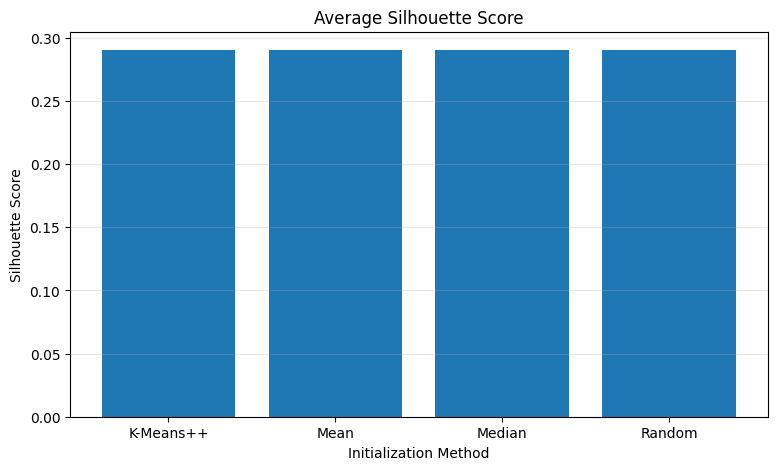

In [224]:
plt.figure(figsize=(9, 5))

plt.bar(
    average_results["Method"],
    average_results["Silhouette Score"]
)

plt.title("Average Silhouette Score")
plt.xlabel("Initialization Method")
plt.ylabel("Silhouette Score")

plt.grid(axis="y", alpha=0.3)
plt.show()

<Figure size 900x500 with 0 Axes>

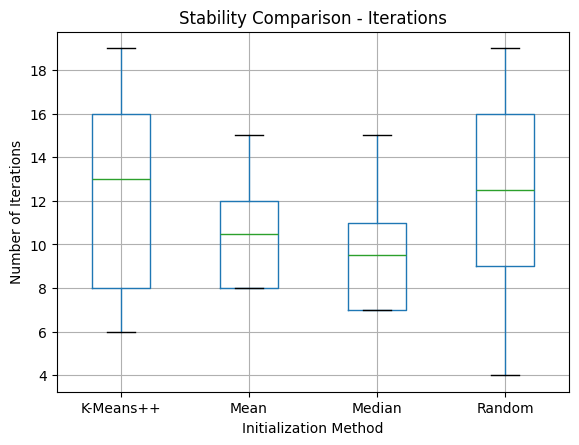

In [225]:
plt.figure(figsize=(9, 5))

results_df.boxplot(
    column="Iterations",
    by="Method"
)

plt.title("Stability Comparison - Iterations")
plt.suptitle("")
plt.xlabel("Initialization Method")
plt.ylabel("Number of Iterations")

plt.show()

<Figure size 900x500 with 0 Axes>

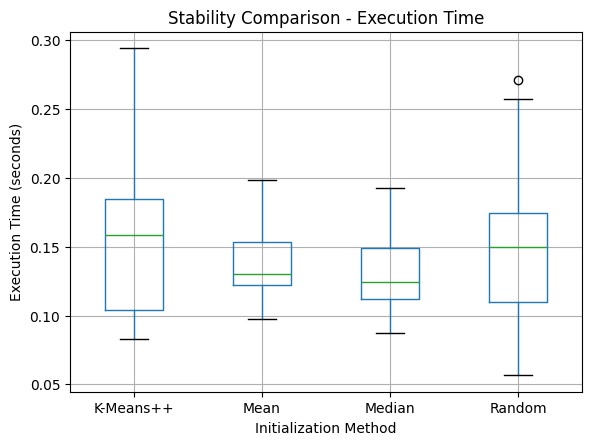

In [226]:
plt.figure(figsize=(9, 5))

results_df.boxplot(
    column="Execution Time",
    by="Method"
)

plt.title("Stability Comparison - Execution Time")
plt.suptitle("")
plt.xlabel("Initialization Method")
plt.ylabel("Execution Time (seconds)")

plt.show()

<Figure size 900x500 with 0 Axes>

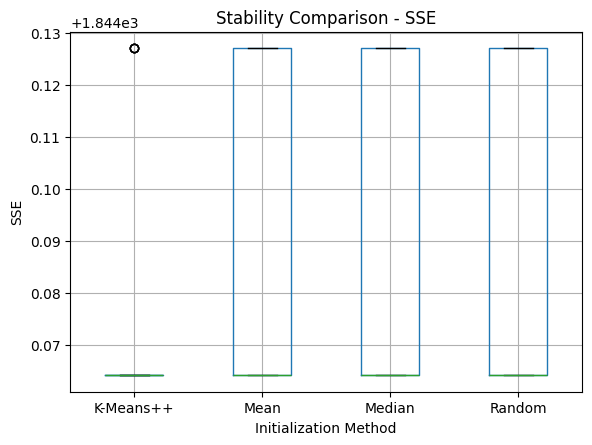

In [227]:
plt.figure(figsize=(9, 5))

results_df.boxplot(
    column="SSE",
    by="Method"
)

plt.title("Stability Comparison - SSE")
plt.suptitle("")
plt.xlabel("Initialization Method")
plt.ylabel("SSE")

plt.show()

## 10. Cluster Visualization and Interpretation

After comparing the four centroid initialization techniques, the final customer clusters are visualized and interpreted.

Principal Component Analysis (PCA) is used to project the six-dimensional spending data into two dimensions for visualization.

The resulting clusters are further analyzed using customer counts, average spending patterns, purchasing channels and geographical regions.

In [228]:
# Generate final clusters using K-Means++

final_initial_centroids = kmeans_plus_plus_initialization(
    data,
    K,
    random_state=42
)

final_labels, final_centroids, final_iterations, final_sse = (
    kmeans_algorithm(
        data,
        final_initial_centroids,
        K
    )
)

# Attach cluster labels to original dataset

df_clustered = df.copy()

df_clustered["Cluster"] = final_labels

print("Final clustering completed!")
print("Number of clusters:", K)
print("Iterations:", final_iterations)
print("SSE:", round(final_sse, 4))

display(df_clustered.head())

Final clustering completed!
Number of clusters: 2
Iterations: 8
SSE: 1844.0641


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Cluster
0,2,3,12669,9656,7561,214,2674,1338,1
1,2,3,7057,9810,9568,1762,3293,1776,1
2,2,3,6353,8808,7684,2405,3516,7844,1
3,1,3,13265,1196,4221,6404,507,1788,0
4,2,3,22615,5410,7198,3915,1777,5185,1


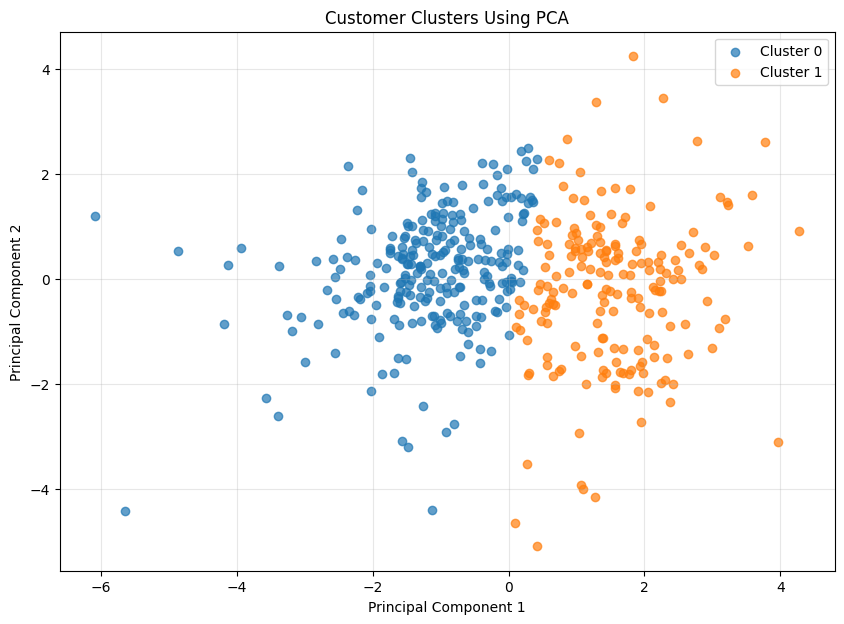

In [229]:
# Import PCA

from sklearn.decomposition import PCA

# Reduce six dimensions to two dimensions

pca = PCA(n_components=2)

pca_data = pca.fit_transform(data)

# Create a DataFrame for visualization

pca_df = pd.DataFrame(
    pca_data,
    columns=["Principal Component 1", "Principal Component 2"]
)

pca_df["Cluster"] = final_labels

# Plot clusters

plt.figure(figsize=(10, 7))

for cluster in sorted(pca_df["Cluster"].unique()):

    cluster_points = pca_df[
        pca_df["Cluster"] == cluster
    ]

    plt.scatter(
        cluster_points["Principal Component 1"],
        cluster_points["Principal Component 2"],
        label=f"Cluster {cluster}",
        alpha=0.7
    )

plt.title("Customer Clusters Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [230]:
# Count customers in each cluster

cluster_counts = df_clustered["Cluster"].value_counts().sort_index()

print("Number of customers in each cluster:")
print(cluster_counts)

# Calculate percentages

cluster_percentages = (
    cluster_counts / len(df_clustered) * 100
)

cluster_distribution = pd.DataFrame({
    "Customer Count": cluster_counts,
    "Percentage": cluster_percentages
})

display(cluster_distribution.round(2))

Number of customers in each cluster:
Cluster
0    252
1    188
Name: count, dtype: int64


,Customer Count,Percentage
Cluster,,
0,252,57.27
1,188,42.73


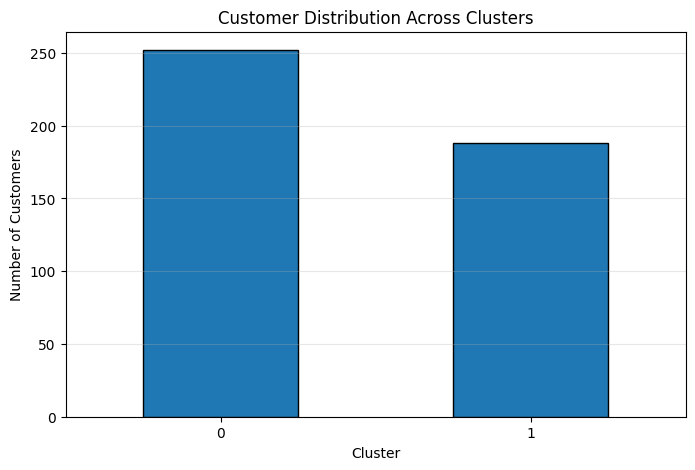

In [231]:
plt.figure(figsize=(8, 5))

cluster_counts.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Customer Distribution Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [232]:
# Calculate average spending for each cluster

cluster_profiles = df_clustered.groupby("Cluster")[features].mean()

print("Average spending by cluster:")

display(cluster_profiles.round(2))

Average spending by cluster:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,13973.13,2401.75,2918.71,3705.67,491.94,1038.04
1,9355.87,10346.36,14697.06,2222.45,6084.51,2177.43


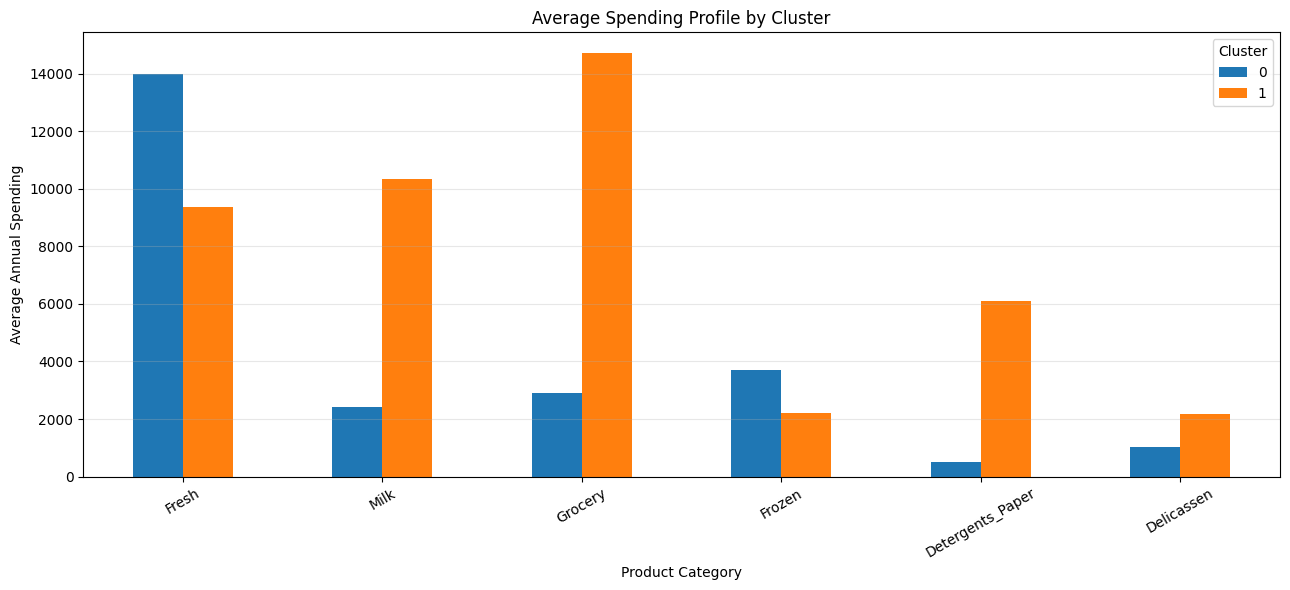

In [233]:
cluster_profiles.T.plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Average Spending Profile by Cluster")
plt.xlabel("Product Category")
plt.ylabel("Average Annual Spending")
plt.xticks(rotation=30)
plt.legend(title="Cluster")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [234]:
# Channel distribution within each cluster

channel_distribution = pd.crosstab(
    df_clustered["Cluster"],
    df_clustered["Channel"]
)

print("Channel distribution by cluster:")

display(channel_distribution)

Channel distribution by cluster:


Channel,1,2
Cluster,,
0,244,8
1,54,134


In [235]:
channel_percentage = pd.crosstab(
    df_clustered["Cluster"],
    df_clustered["Channel"],
    normalize="index"
) * 100

print("Channel percentage within each cluster:")

display(channel_percentage.round(2))

Channel percentage within each cluster:


Channel,1,2
Cluster,,
0,96.83,3.17
1,28.72,71.28


In [236]:
# Region distribution within each cluster

region_distribution = pd.crosstab(
    df_clustered["Cluster"],
    df_clustered["Region"]
)

print("Region distribution by cluster:")

display(region_distribution)

Region distribution by cluster:


Region,1,2,3
Cluster,,,
0,48,28,176
1,29,19,140


In [237]:
region_percentage = pd.crosstab(
    df_clustered["Cluster"],
    df_clustered["Region"],
    normalize="index"
) * 100

print("Region percentage within each cluster:")

display(region_percentage.round(2))

Region percentage within each cluster:


Region,1,2,3
Cluster,,,
0,19.05,11.11,69.84
1,15.43,10.11,74.47


In [238]:
# Combine cluster sizes and average spending

cluster_summary = df_clustered.groupby("Cluster").agg(
    Customer_Count=("Cluster", "count"),
    Fresh=("Fresh", "mean"),
    Milk=("Milk", "mean"),
    Grocery=("Grocery", "mean"),
    Frozen=("Frozen", "mean"),
    Detergents_Paper=("Detergents_Paper", "mean"),
    Delicassen=("Delicassen", "mean")
)

display(cluster_summary.round(2))

,Customer_Count,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,,
0,252,13973.13,2401.75,2918.71,3705.67,491.94,1038.04
1,188,9355.87,10346.36,14697.06,2222.45,6084.51,2177.43


### 10.9 Interpretation of Customer Clusters

The final clustering results identified two customer segments containing 252 customers (57.27%) and 188 customers (42.73%), respectively.

The average spending profiles revealed differences in purchasing behaviour.

Cluster 0 demonstrated higher average spending on Fresh and Frozen products, whereas Cluster 1 showed higher average spending on Milk, Grocery, Detergents_Paper and Delicassen products.

The Channel distribution provided an additional insight. Approximately 96.83% of Cluster 0 consisted of Horeca customers, while 71.28% of Cluster 1 consisted of Retail customers. This indicates a strong association between the spending-based clusters and customer channel.

The regional distribution was relatively similar across both clusters, with Region 3 accounting for the largest proportion in each group.

The PCA visualization showed a degree of separation between the clusters, although some overlap remained. This is consistent with the relatively modest Silhouette Score.

Overall, the results indicate that the K-Means algorithm identified two groups with different purchasing patterns, particularly in relation to customer channel and product-category spending.

In [239]:
# Final average performance comparison

final_comparison = results_df.groupby("Method").agg({
    "Iterations": "mean",
    "Execution Time": "mean",
    "SSE": "mean",
    "Silhouette Score": "mean"
}).reset_index()

display(final_comparison.round(6))

,Method,Iterations,Execution Time,SSE,Silhouette Score
0,K-Means++,12.533333,0.158065,1844.072464,0.290350
1,Mean,10.233333,0.135062,1844.089254,0.290392
2,Median,9.300000,0.126966,1844.089254,0.290392
3,Random,12.200000,0.150398,1844.082957,0.290376


In [240]:
# Standard deviation of performance metrics

final_stability = results_df.groupby("Method").agg({
    "Iterations": "std",
    "Execution Time": "std",
    "SSE": "std",
    "Silhouette Score": "std"
}).reset_index()

display(final_stability.round(6))

,Method,Iterations,Execution Time,SSE,Silhouette Score
0,K-Means++,4.407934,0.055814,0.021769,0.000055
1,Mean,2.144493,0.028257,0.031372,0.000080
2,Median,2.306662,0.030222,0.031372,0.000080
3,Random,4.373904,0.055181,0.029346,0.000075


In [241]:
# Calculate iteration improvement relative to Random

random_iterations = final_comparison.loc[
    final_comparison["Method"] == "Random",
    "Iterations"
].iloc[0]

final_comparison["Iteration Improvement (%)"] = (
    (random_iterations - final_comparison["Iterations"])
    / random_iterations
) * 100

display(final_comparison.round(4))

,Method,Iterations,Execution Time,SSE,Silhouette Score,Iteration Improvement (%)
0,K-Means++,12.5333,0.1581,1844.0725,0.2903,-2.7322
1,Mean,10.2333,0.1351,1844.0893,0.2904,16.1202
2,Median,9.3000,0.1270,1844.0893,0.2904,23.7705
3,Random,12.2000,0.1504,1844.0830,0.2904,0.0000


In [242]:
# Calculate runtime improvement relative to Random

random_time = final_comparison.loc[
    final_comparison["Method"] == "Random",
    "Execution Time"
].iloc[0]

final_comparison["Runtime Improvement (%)"] = (
    (random_time - final_comparison["Execution Time"])
    / random_time
) * 100

display(final_comparison.round(4))

,Method,Iterations,Execution Time,SSE,Silhouette Score,Iteration Improvement (%),Runtime Improvement (%)
0,K-Means++,12.5333,0.1581,1844.0725,0.2903,-2.7322,-5.0977
1,Mean,10.2333,0.1351,1844.0893,0.2904,16.1202,10.1972
2,Median,9.3000,0.1270,1844.0893,0.2904,23.7705,15.5805
3,Random,12.2000,0.1504,1844.0830,0.2904,0.0000,0.0000


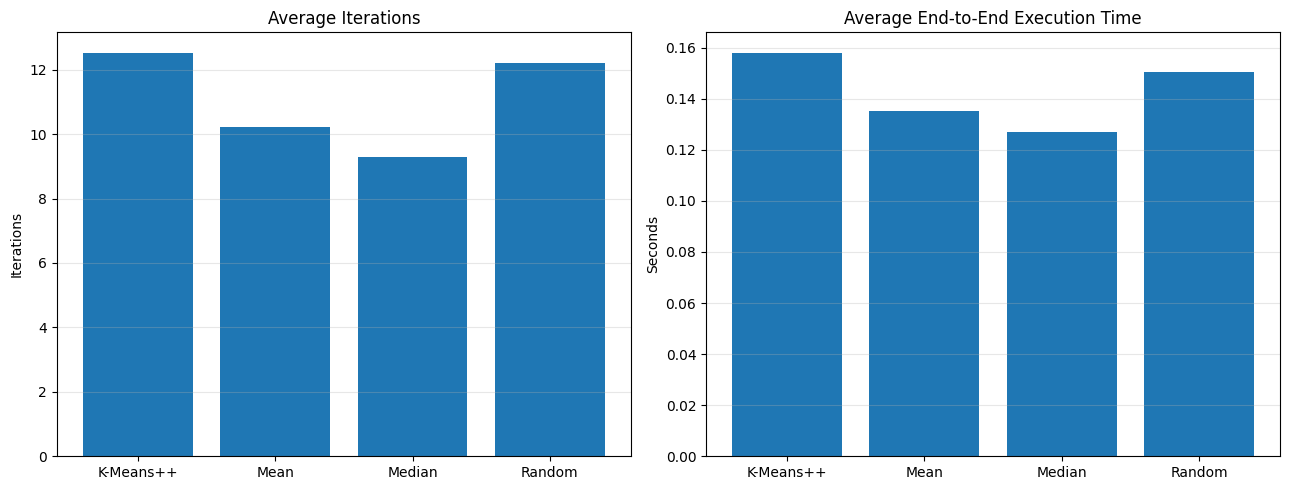

In [243]:
# Compare average iterations and runtime

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(
    final_comparison["Method"],
    final_comparison["Iterations"]
)

axes[0].set_title("Average Iterations")
axes[0].set_ylabel("Iterations")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    final_comparison["Method"],
    final_comparison["Execution Time"]
)

axes[1].set_title("Average End-to-End Execution Time")
axes[1].set_ylabel("Seconds")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 12. Sensitivity Analysis with K=3

A sensitivity analysis is conducted to investigate whether the performance of the centroid initialization techniques changes when the number of clusters is increased from K=2 to K=3.

The same dataset, preprocessing procedure, K-Means implementation and evaluation metrics are used.

The experiment compares Random, Mean, Median and K-Means++ initialization using 30 repeated trials for each method.

The primary objective is to examine whether the relative performance of the initialization methods is consistent across different values of K.

In [244]:
# Set number of clusters to 3

K_SENSITIVITY = 3

N_RUNS = 30

results_k3 = []

print("Sensitivity experiment")
print("Number of clusters:", K_SENSITIVITY)
print("Number of trials:", N_RUNS)

Sensitivity experiment
Number of clusters: 3
Number of trials: 30


In [245]:
# Run 30 experiments for K=3

for run in range(N_RUNS):

    seed = 200 + run

    # Random initialization
    start_time = time.perf_counter()

    initial_random = random_initialization(
        data, K_SENSITIVITY, random_state=seed
    )

    labels, centroids, iterations, sse = kmeans_algorithm(
        data, initial_random, K_SENSITIVITY
    )

    execution_time = time.perf_counter() - start_time

    results_k3.append({
        "Run": run + 1,
        "Method": "Random",
        "Iterations": iterations,
        "Execution Time": execution_time,
        "SSE": sse,
        "Silhouette Score": silhouette_score(data, labels)
    })

    # Select sorting feature
    rng = np.random.default_rng(seed)
    feature_index = rng.integers(0, data.shape[1])

    # Mean initialization
    start_time = time.perf_counter()

    initial_mean = mean_initialization(
        data, K_SENSITIVITY, feature_index
    )

    labels, centroids, iterations, sse = kmeans_algorithm(
        data, initial_mean, K_SENSITIVITY
    )

    execution_time = time.perf_counter() - start_time

    results_k3.append({
        "Run": run + 1,
        "Method": "Mean",
        "Iterations": iterations,
        "Execution Time": execution_time,
        "SSE": sse,
        "Silhouette Score": silhouette_score(data, labels)
    })

    # Median initialization
    start_time = time.perf_counter()

    initial_median = median_initialization(
        data, K_SENSITIVITY, feature_index
    )

    labels, centroids, iterations, sse = kmeans_algorithm(
        data, initial_median, K_SENSITIVITY
    )

    execution_time = time.perf_counter() - start_time

    results_k3.append({
        "Run": run + 1,
        "Method": "Median",
        "Iterations": iterations,
        "Execution Time": execution_time,
        "SSE": sse,
        "Silhouette Score": silhouette_score(data, labels)
    })

    # K-Means++ initialization
    start_time = time.perf_counter()

    initial_kpp = kmeans_plus_plus_initialization(
        data, K_SENSITIVITY, random_state=seed
    )

    labels, centroids, iterations, sse = kmeans_algorithm(
        data, initial_kpp, K_SENSITIVITY
    )

    execution_time = time.perf_counter() - start_time

    results_k3.append({
        "Run": run + 1,
        "Method": "K-Means++",
        "Iterations": iterations,
        "Execution Time": execution_time,
        "SSE": sse,
        "Silhouette Score": silhouette_score(data, labels)
    })

print("K=3 experiments completed!")
print("Total runs:", len(results_k3))

K=3 experiments completed!
Total runs: 120


In [246]:
# Convert results into DataFrame

results_k3_df = pd.DataFrame(results_k3)

# Calculate average performance

average_k3 = results_k3_df.groupby("Method").agg({
    "Iterations": "mean",
    "Execution Time": "mean",
    "SSE": "mean",
    "Silhouette Score": "mean"
}).reset_index()

display(average_k3.round(6))

,Method,Iterations,Execution Time,SSE,Silhouette Score
0,K-Means++,15.633333,0.244908,1572.682179,0.238472
1,Mean,12.566667,0.202084,1575.987000,0.205750
2,Median,14.266667,0.218971,1575.990386,0.205518
3,Random,15.100000,0.226467,1573.106746,0.229262


In [247]:
# Calculate standard deviation

stability_k3 = results_k3_df.groupby("Method").agg({
    "Iterations": "std",
    "Execution Time": "std",
    "SSE": "std",
    "Silhouette Score": "std"
}).reset_index()

display(stability_k3.round(6))

,Method,Iterations,Execution Time,SSE,Silhouette Score
0,K-Means++,5.690181,0.080717,24.884223,0.031535
1,Mean,6.328280,0.079909,10.332302,0.024421
2,Median,6.787074,0.093799,10.286074,0.024199
3,Random,6.519731,0.090819,29.213316,0.034718


In [248]:
# Add K column to both result tables

comparison_k2_k3 = pd.concat([
    average_results.assign(K=2),
    average_k3.assign(K=3)
], ignore_index=True)

# Arrange columns

comparison_k2_k3 = comparison_k2_k3[
    [
        "K",
        "Method",
        "Iterations",
        "Execution Time",
        "SSE",
        "Silhouette Score"
    ]
]

display(comparison_k2_k3.round(6))

,K,Method,Iterations,Execution Time,SSE,Silhouette Score
0,2,K-Means++,12.533333,0.158065,1844.072464,0.290350
1,2,Mean,10.233333,0.135062,1844.089254,0.290392
2,2,Median,9.300000,0.126966,1844.089254,0.290392
3,2,Random,12.200000,0.150398,1844.082957,0.290376
4,3,K-Means++,15.633333,0.244908,1572.682179,0.238472
5,3,Mean,12.566667,0.202084,1575.987000,0.205750
6,3,Median,14.266667,0.218971,1575.990386,0.205518
7,3,Random,15.100000,0.226467,1573.106746,0.229262


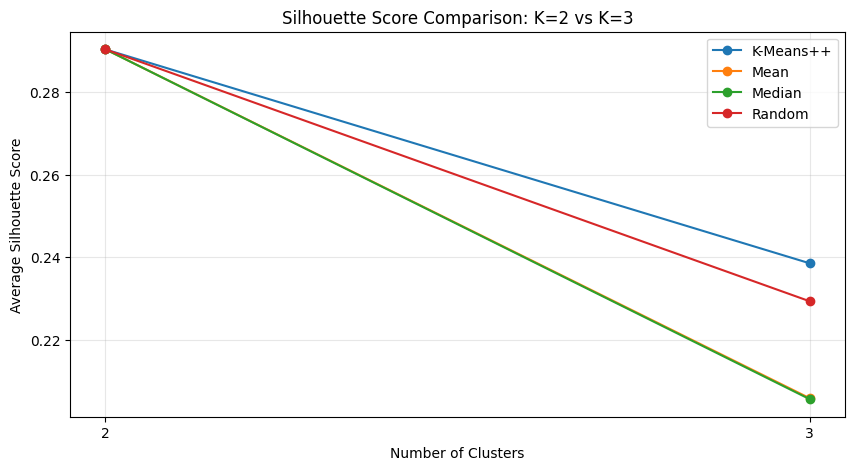

In [249]:
# Compare silhouette scores for K=2 and K=3

plt.figure(figsize=(10, 5))

for method in comparison_k2_k3["Method"].unique():

    method_data = comparison_k2_k3[
        comparison_k2_k3["Method"] == method
    ]

    plt.plot(
        method_data["K"],
        method_data["Silhouette Score"],
        marker="o",
        label=method
    )

plt.title("Silhouette Score Comparison: K=2 vs K=3")
plt.xlabel("Number of Clusters")
plt.ylabel("Average Silhouette Score")
plt.xticks([2, 3])
plt.legend()
plt.grid(alpha=0.3)

plt.show()

## 13. Research Conclusion

This research investigated the effect of different centroid initialization techniques on the performance of the K-Means clustering algorithm using the UCI Wholesale Customers dataset.

Four initialization techniques were implemented and compared: Random, Mean-based, Median-based and K-Means++ initialization. The K-Means algorithm was implemented from scratch using Python and NumPy. The dataset was preprocessed using logarithmic transformation and StandardScaler before clustering.

The optimal number of clusters was investigated using the Elbow Method and Silhouette Score. K=2 was selected for the primary experiments because it achieved the highest Silhouette Score of 0.2903. K=3 was additionally evaluated through a sensitivity experiment.

For K=2, Median initialization achieved the lowest average number of iterations (9.30) and the lowest average execution time (0.126966 seconds) among the tested methods. K-Means++ achieved the lowest average SSE, while Mean and Median initialization produced the highest average Silhouette Score. However, the differences in clustering quality were small.

For K=3, Mean initialization achieved the lowest average iteration count and execution time, whereas K-Means++ produced the lowest SSE and highest Silhouette Score.

The results indicate that the choice of initialization technique influences the convergence behaviour of K-Means. However, the best-performing method depends on the selected evaluation metric and the number of clusters.

The customer segmentation analysis also revealed two distinct purchasing profiles. One group showed higher spending on Fresh and Frozen products, while the other showed higher spending on Milk, Grocery and Detergents_Paper. The clusters also showed a strong association with customer channel.

Overall, the study demonstrates that alternative centroid initialization techniques can influence the computational efficiency and clustering behaviour of K-Means. No single initialization technique was found to be universally superior across all evaluation criteria.

### 13.6 Limitations

1. The experiments were conducted using a single real-world dataset containing 440 customer records. The findings may not generalize to other datasets or domains.

2. The Mean-based and Median-based initialization techniques used in this study are feature-guided experimental variants inspired by the selected research paper. They are not claimed to be exact reproductions of all initialization formulas proposed in the original paper.

3. The study evaluated a limited range of cluster counts, primarily K=2 and K=3, with the Elbow and Silhouette analyses covering K=1 to K=10.

4. The dataset contains overlapping customer purchasing patterns, resulting in relatively modest Silhouette Scores.

5. Execution times are small and may be influenced by the Google Colab environment, system load and measurement overhead.

6. The study does not establish statistical significance for the observed differences between initialization techniques.

7. The clustering results depend on the selected preprocessing method, features and convergence criteria.

### 13.7 Future Work

1. Evaluate the proposed initialization techniques on larger datasets from different application domains.

2. Investigate alternative initialization strategies, including density-based and hierarchical approaches.

3. Explore feature selection and dimensionality reduction techniques to improve clustering quality.

4. Conduct statistical significance tests to determine whether performance differences between initialization methods are meaningful.

5. Investigate different preprocessing techniques, including RobustScaler and alternative transformations.

6. Compare K-Means with other clustering algorithms such as DBSCAN, Agglomerative Clustering and Gaussian Mixture Models.

7. Extend the experiments to larger values of K and evaluate the scalability of the initialization methods.